In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [3]:
df=pd.read_csv("train.txt", sep=";",header=None, names=["text","emotion"])
df.head()

,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [4]:
df.isnull().sum()

text       0
emotion    0
dtype: int64

In [5]:
df["emotion"].unique()

<ArrowStringArray>
['sadness', 'anger', 'love', 'surprise', 'fear', 'joy']
Length: 6, dtype: str

In [6]:
unique_emotions=df["emotion"].unique() 
emotion_number={} 
i=0 
for emo in unique_emotions: 
    emotion_number[emo]=i 
    i=i+1 
df["emotion"]=df["emotion"].map(emotion_number) 

In [7]:
df.head()

,text,emotion
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,1
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,1


In [8]:
df["text"]=df["text"].apply(lambda x:x.lower())

In [9]:
import string 
def remove_punch(txt): 
    return txt.translate(str.maketrans("","",string.punctuation)) 
df["text"].apply(remove_punch)

0                                  i didnt feel humiliated
1        i can go from feeling so hopeless to so damned...
2         im grabbing a minute to post i feel greedy wrong
3        i am ever feeling nostalgic about the fireplac...
4                                     i am feeling grouchy
                               ...                        
15995    i just had a very brief time in the beanbag an...
15996    i am now turning and i feel pathetic that i am...
15997                       i feel strong and good overall
15998    i feel like this was such a rude comment and i...
15999    i know a lot but i feel so stupid because i ca...
Name: text, Length: 16000, dtype: str

In [10]:
def remove_numbers(txt): 
    new=""
    for i in txt: 
        if not i.isdigit(): 
            new=new+i
    return new
df["text"]=df["text"].apply(remove_numbers) 

In [11]:
def remove_emojis(txt): 
    new=""
    for i in txt: 
        if i.isascii(): 
            new=new+i 
    return new
df["text"]=df["text"].apply(remove_emojis) 

In [12]:
import nltk

In [13]:
from nltk.corpus import stopwords 
from nltk.tokenize import word_tokenize 
nltk.download("punkt")
nltk.download("stopwords")

[nltk_data] Downloading package punkt to /Users/amansingh/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/amansingh/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [14]:
stopwords=set(stopwords.words("english"))

In [15]:
len(stopwords) 

198

In [16]:
df.loc[1]["text"]

'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake'

In [17]:
def remove(txt): 
    words=word_tokenize(txt) 
    cleaned=[] 
    for i in words: 
        if not i in stopwords: 
            cleaned.append(i) 
    return " ".join(cleaned) 

df["text"]=df["text"].apply(remove) 

In [18]:
from sklearn.model_selection import train_test_split 
x=df["text"] 
y=df["emotion"]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42) 

In [30]:
from sklearn.metrics import accuracy_score,f1_score,classification_report,confusion_matrix
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier 
from sklearn.svm import SVC 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
bow_vectorizer = CountVectorizer()
x_train_bow = bow_vectorizer.fit_transform(x_train)
x_test_bow = bow_vectorizer.transform(x_test)


nb_model_count_vector = MultinomialNB()
nb_model_count_vector.fit(x_train_bow, y_train)

models={"logistic Regression":LogisticRegression(), 
        "KNN": KNeighborsClassifier(), 
        "NaiveBayes":MultinomialNB(), 
        "Decesion Tree":DecisionTreeClassifier(), 
        "SVM":SVC()
        }
result_countvectorizer=[]
for name,model in models.items():
    model.fit(x_train_bow,y_train) 
    y_pred_bow=model.predict(x_test_bow)
    y_pred_train_bow=model.predict(x_train_bow)
    acc_train=accuracy_score(y_train,y_pred_train_bow)
    acc_test=accuracy_score(y_test,y_pred_bow) 
    train_f1 = f1_score(y_train, y_pred_train_bow, average="weighted", zero_division=0)
    test_f1 = f1_score(y_test, y_pred_bow, average="weighted", zero_division=0)
    result_countvectorizer.append({"model":name, 
                   "Vectorizer":"CountVectorizer",
                   "Train Accuracy":round(acc_train,4),
                   "Test Accuracy":round(acc_test,4), 
                   "Train Weighted F1":round(train_f1,4),
                   "Test Weighted F1":round(test_f1,4),
                   "Accuracy Gap": round(acc_train - acc_test,4),
                                   
                  })



In [20]:
results_df = pd.DataFrame(result_countvectorizer)
results_df.sort_values(by="Test Accuracy", ascending=False)

,model,Vectorizer,Train Accuracy,Test Accuracy,Train Weighted F1,Test Weighted F1,Accuracy Gap
0,logistic Regression,CountVectorizer,0.9872,0.8888,0.9872,0.8877,0.0984
3,Decesion Tree,CountVectorizer,0.9979,0.8700,0.9979,0.8703,0.1279
4,SVM,CountVectorizer,0.9737,0.8225,0.9733,0.8154,0.1512
2,NaiveBayes,CountVectorizer,0.9030,0.7678,0.8958,0.7368,0.1352
1,KNN,CountVectorizer,0.7309,0.5500,0.7271,0.5359,0.1809


In [21]:
Tfidf_vectorizer=TfidfVectorizer() 
x_train_Tfidf=Tfidf_vectorizer.fit_transform(x_train) 
x_test_Tfidf=Tfidf_vectorizer.transform(x_test)

models={"logistic Regression":LogisticRegression(), 
        "KNN": KNeighborsClassifier(), 
        "NaiveBayes":MultinomialNB(), 
        "Decesion Tree":DecisionTreeClassifier(), 
        "SVM":SVC()
        }
result_Tfidf=[]
for name,model in models.items():
    model.fit(x_train_Tfidf,y_train) 
    y_pred_Tfidf=model.predict(x_test_Tfidf)
    y_pred_train_Tfidf=model.predict(x_train_Tfidf)
    acc_train=accuracy_score(y_train,y_pred_train_Tfidf)
    acc_test=accuracy_score(y_test,y_pred_Tfidf) 
    train_f1 = f1_score(y_train, y_pred_train_Tfidf, average="weighted", zero_division=0)
    test_f1 = f1_score(y_test, y_pred_Tfidf, average="weighted", zero_division=0)
    result_Tfidf.append({"model":name, 
                   "Vectorizer":"TFIDF",
                   "Train Accuracy":round(acc_train,4),
                   "Test Accuracy":round(acc_test,4), 
                   "Train Weighted F1":round(train_f1,4),
                   "Test Weighted F1":round(test_f1,4),
                   "Accuracy Gap": round(acc_train - acc_test,4),
                   
                  })


In [22]:
results_df_Tfidf = pd.DataFrame(result_Tfidf)
results_df_Tfidf.sort_values(by="Test Accuracy", ascending=False)

,model,Vectorizer,Train Accuracy,Test Accuracy,Train Weighted F1,Test Weighted F1,Accuracy Gap
3,Decesion Tree,TFIDF,0.9979,0.8656,0.9979,0.8653,0.1323
0,logistic Regression,TFIDF,0.9467,0.8616,0.9456,0.8560,0.0852
4,SVM,TFIDF,0.9916,0.8516,0.9915,0.8457,0.1400
1,KNN,TFIDF,0.8681,0.7806,0.8670,0.7757,0.0875
2,NaiveBayes,TFIDF,0.7496,0.6609,0.6997,0.5826,0.0887


In [23]:


# Combine both results
results_df = pd.concat(
    [results_df,results_df_Tfidf],
    ignore_index=True
)

# Sort by Test Accuracy
results_df.sort_values(
    by="Test Accuracy",
    ascending=False
)

,model,Vectorizer,Train Accuracy,Test Accuracy,Train Weighted F1,Test Weighted F1,Accuracy Gap
0,logistic Regression,CountVectorizer,0.9872,0.8888,0.9872,0.8877,0.0984
3,Decesion Tree,CountVectorizer,0.9979,0.8700,0.9979,0.8703,0.1279
8,Decesion Tree,TFIDF,0.9979,0.8656,0.9979,0.8653,0.1323
5,logistic Regression,TFIDF,0.9467,0.8616,0.9456,0.8560,0.0852
9,SVM,TFIDF,0.9916,0.8516,0.9915,0.8457,0.1400
4,SVM,CountVectorizer,0.9737,0.8225,0.9733,0.8154,0.1512
6,KNN,TFIDF,0.8681,0.7806,0.8670,0.7757,0.0875
2,NaiveBayes,CountVectorizer,0.9030,0.7678,0.8958,0.7368,0.1352
7,NaiveBayes,TFIDF,0.7496,0.6609,0.6997,0.5826,0.0887
1,KNN,CountVectorizer,0.7309,0.5500,0.7271,0.5359,0.1809


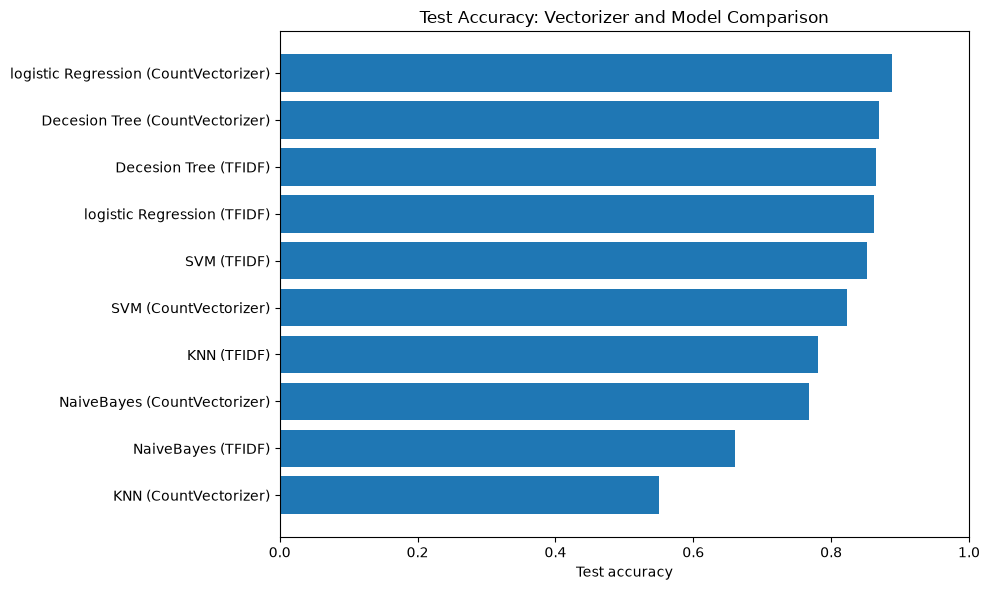

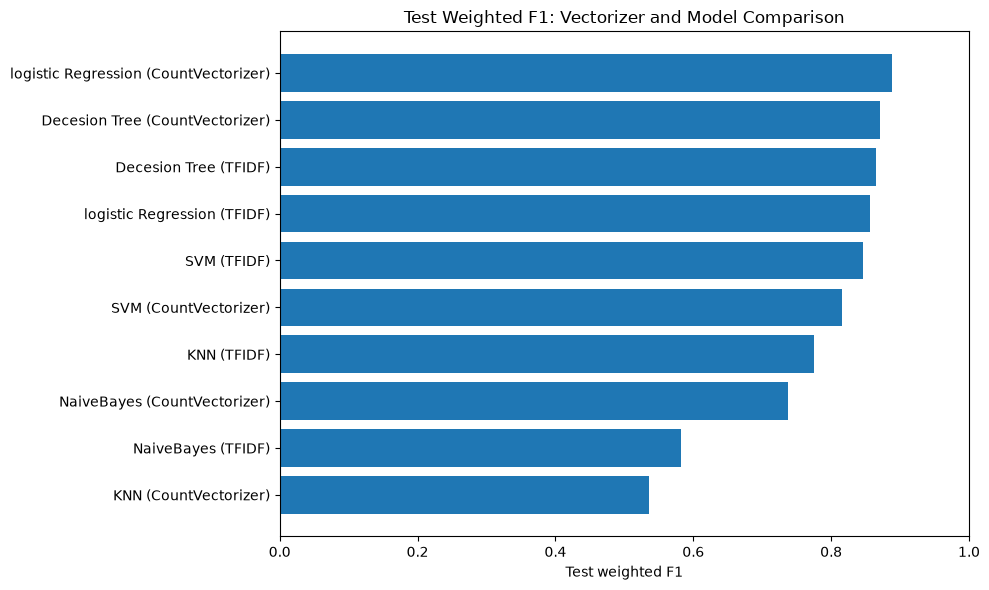

In [24]:
plot_df = results_df.sort_values("Test Accuracy", ascending=True)
labels = plot_df["model"] + " (" + plot_df["Vectorizer"] + ")"

plt.figure(figsize=(10, 6))
plt.barh(labels, plot_df["Test Accuracy"])
plt.xlabel("Test accuracy")
plt.title("Test Accuracy: Vectorizer and Model Comparison")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.barh(labels, plot_df["Test Weighted F1"])
plt.xlabel("Test weighted F1")
plt.title("Test Weighted F1: Vectorizer and Model Comparison")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [25]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate

pipeline = make_pipeline(
    CountVectorizer(),
    LogisticRegression(max_iter=1000)
)

cv_results = cross_validate(
    pipeline,
    x_train,
    y_train,
    cv=5,
    scoring={
        "accuracy": "accuracy",
        "f1_weighted": "f1_weighted"
    },
    return_train_score=True
)

print("Mean CV Train Accuracy:",
      round(cv_results["train_accuracy"].mean(), 4))

print("Mean CV Validation Accuracy:",
      round(cv_results["test_accuracy"].mean(), 4))

print("Mean CV Validation F1:",
      round(cv_results["test_f1_weighted"].mean(), 4))


Mean CV Train Accuracy: 0.9888
Mean CV Validation Accuracy: 0.8875
Mean CV Validation F1: 0.8861


In [28]:
pipeline.fit(x_train, y_train)

y_pred = pipeline.predict(x_test)

print(classification_report(y_test, y_pred, zero_division=0))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.93      0.93       946
           1       0.89      0.85      0.87       427
           2       0.84      0.76      0.80       296
           3       0.86      0.72      0.78       113
           4       0.86      0.84      0.85       397
           5       0.88      0.94      0.91      1021

    accuracy                           0.89      3200
   macro avg       0.88      0.84      0.86      3200
weighted avg       0.89      0.89      0.89      3200

[[878  24   7   1  13  23]
 [ 25 365   0   2  15  20]
 [  5   2 225   1   4  59]
 [  5   0   1  81  20   6]
 [ 18  16   3   7 332  21]
 [ 16   5  31   2   4 963]]


In [31]:
param_grid = {
    "logisticregression__C": [0.001, 0.01, 0.1, 1, 10]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="f1_macro",
    return_train_score=True,
    n_jobs=-1
)

grid.fit(x_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV macro F1:", round(grid.best_score_, 4))

Best parameters: {'logisticregression__C': 1}
Best CV macro F1: 0.8462


In [32]:
best_model = grid.best_estimator_
y_pred = best_model.predict(x_test)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(
    "Test Macro F1:",
    round(f1_score(y_test, y_pred, average="macro"), 4)
)
print(
    "Test Weighted F1:",
    round(f1_score(y_test, y_pred, average="weighted"), 4)
)

print(classification_report(y_test, y_pred, zero_division=0))

Test Accuracy: 0.8888
Test Macro F1: 0.8562
Test Weighted F1: 0.8877
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       946
           1       0.89      0.85      0.87       427
           2       0.84      0.76      0.80       296
           3       0.86      0.72      0.78       113
           4       0.86      0.84      0.85       397
           5       0.88      0.94      0.91      1021

    accuracy                           0.89      3200
   macro avg       0.88      0.84      0.86      3200
weighted avg       0.89      0.89      0.89      3200



In [33]:
x.head()

0                                didnt feel humiliated
1    go feeling hopeless damned hopeful around some...
2            im grabbing minute post feel greedy wrong
3    ever feeling nostalgic fireplace know still pr...
4                                      feeling grouchy
Name: text, dtype: str

In [35]:
import joblib

# Save the best fitted pipeline (CountVectorizer + Logistic Regression)
best_model = grid.best_estimator_

joblib.dump(best_model, "sentiment_analysis_model.pkl")
joblib.dump(unique_emotions.tolist(),"Emotions.pkl")
print("Model saved successfully!")

Model saved successfully!
